In [ ]:
!curl https://course-v3.fast.ai/setup/colab | bash


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0curl: (6) Could not resolve host: course-v3.fast.ai


In [ ]:
!pip install torch torchvision
import os


In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
from fastai import *
from fastai.vision import *

In [ ]:
cd /content/drive/MyDrive/DATASET/Data/Train

/content/drive/MyDrive/DATASET/Data/Train


In [ ]:
path = ""
bs = 32
data = ImageDataBunch.from_folder(path, valid_pct=0.3, bs=bs)
data.normalize(imagenet_stats)

ImageDataBunch;

Train: LabelList (581 items)
x: ImageList
Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432)
y: CategoryList
metal,metal,metal,metal,metal
Path: .;

Valid: LabelList (248 items)
x: ImageList
Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432),Image (3, 288, 432)
y: CategoryList
jazz,country,pop,hiphop,rock
Path: .;

Test: None

In [ ]:
print(data.classes)
len(data.classes),data.c

['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


(10, 10)

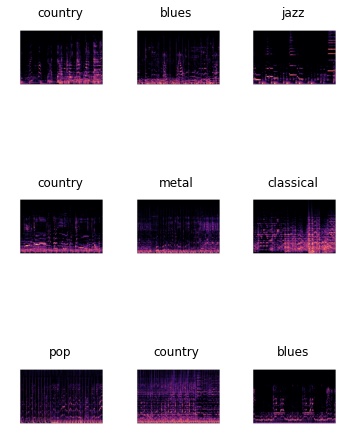

In [ ]:
data.show_batch(rows=3, figsize=(5,8))

In [ ]:
#learner = create_cnn(data, models.de, metrics=accuracy)
learner = cnn_learner(data, models.densenet121,
            pretrained=False)

In [ ]:
learner.fit_one_cycle(10)

epoch,train_loss,valid_loss,time


RuntimeError: ignored

In [ ]:
learner.save('densenet121_Tooraj')

In [ ]:
interp = ClassificationInterpretation.from_learner(learner)

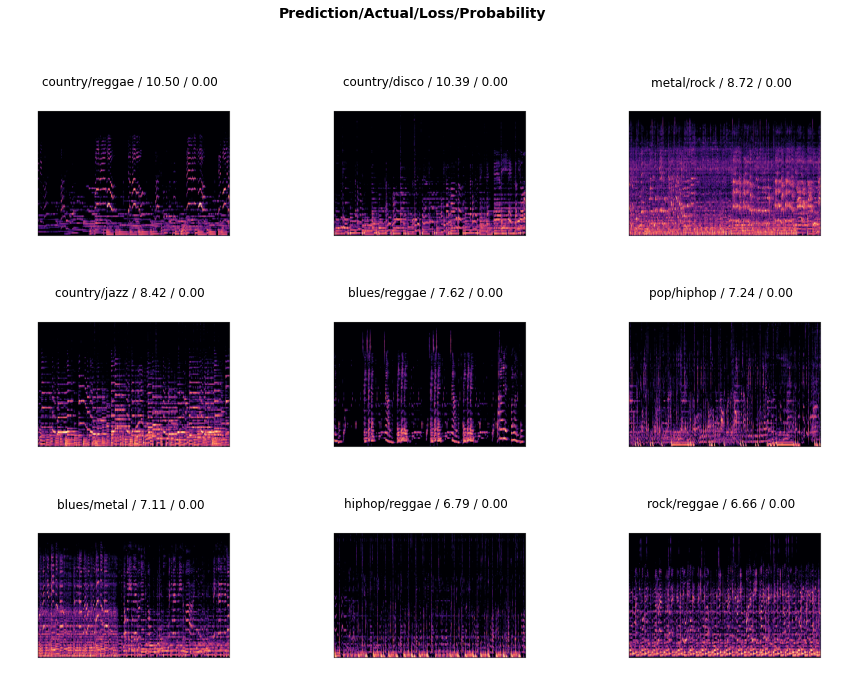

In [ ]:
interp.plot_top_losses(9, figsize=(15,11))

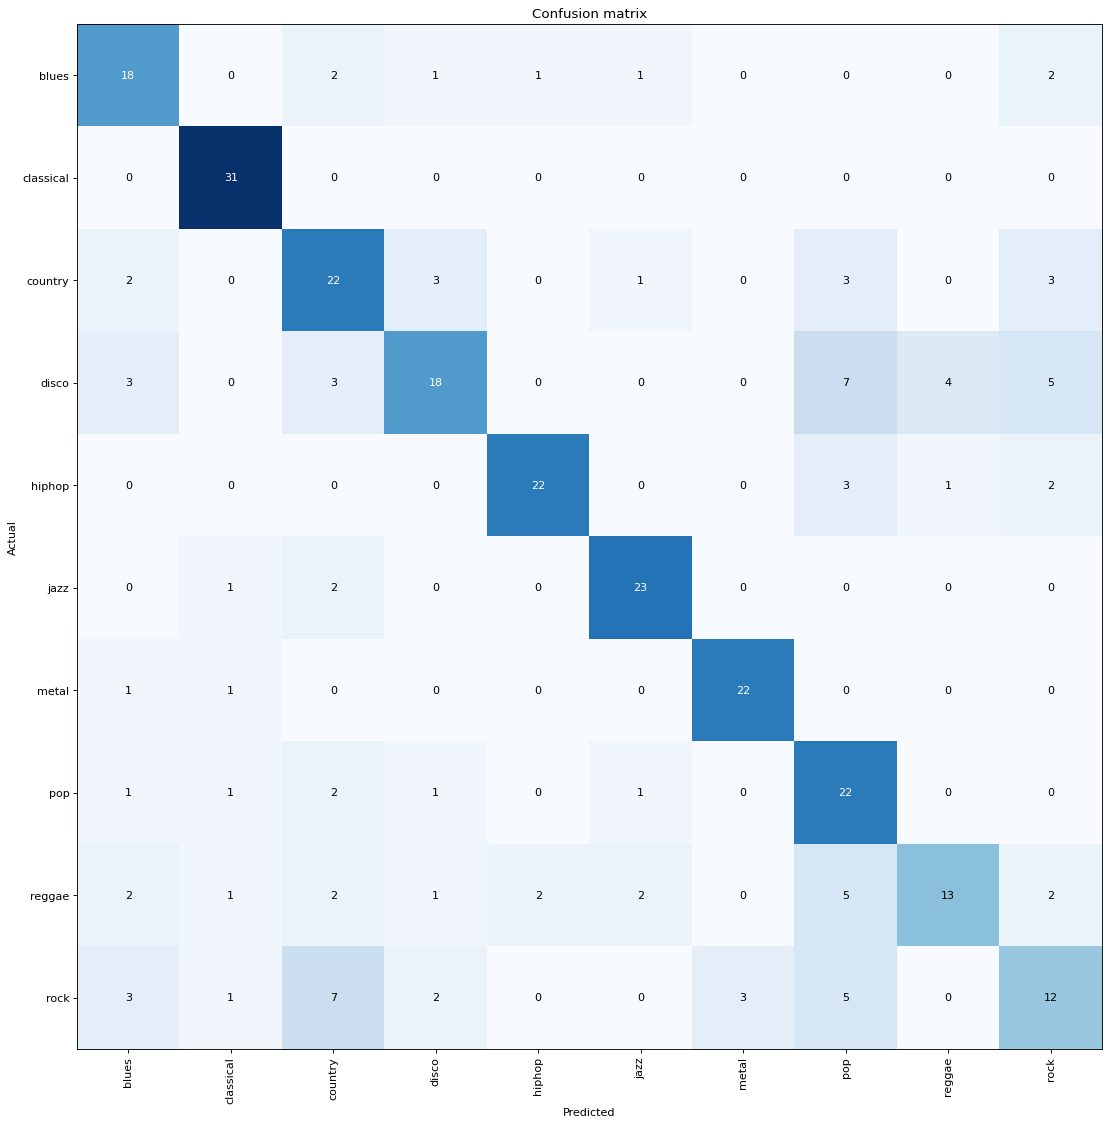

In [ ]:
interp.plot_confusion_matrix(figsize=(14,14), dpi=80)


In [ ]:
interp.most_confused(min_val=2)


[('reggae', 'pop', 7),
 ('rock', 'country', 7),
 ('country', 'rock', 6),
 ('disco', 'rock', 6),
 ('country', 'blues', 5),
 ('disco', 'hiphop', 4),
 ('rock', 'metal', 4),
 ('blues', 'country', 3),
 ('disco', 'pop', 3),
 ('jazz', 'country', 3),
 ('pop', 'rock', 3),
 ('rock', 'disco', 3),
 ('blues', 'jazz', 2),
 ('blues', 'metal', 2),
 ('blues', 'rock', 2),
 ('classical', 'jazz', 2),
 ('country', 'jazz', 2),
 ('jazz', 'classical', 2),
 ('jazz', 'disco', 2),
 ('metal', 'rock', 2),
 ('pop', 'blues', 2),
 ('pop', 'hiphop', 2),
 ('reggae', 'blues', 2),
 ('reggae', 'country', 2),
 ('rock', 'pop', 2)]